In [2]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *
from Eigenvalues import *

import config

# Antidark

In [3]:
# Create solitons
L = 50
N = 400_001
eps = 0.01
k = 0.5+eps
#0.1

pars = {"k":k}

c_1 = np.sqrt(2) + 0.1 #1 + np.sqrt(2)

# Theretical solitons
w_dark, x_dark = soliton(c_1, k, soliton_type="anti", L=L, N=N)#, as_func=True) #c=0

Creating soliton...
Soliton created


In [29]:
h = x_dark[1] - x_dark[0]

D1 = D1_neumann_centered(N, h)
D2 = D2_neumann_centered(N, h)

M, A, B = build_linearized_matrix(w_dark, D1, D2, k, c_1)#, profs=(eta, theta))

evals, evecs = spla.eigs(M, k=128, which='LR')#, sigma=1)

In [31]:
evals

array([26324713.23020246+0.j, 26321839.2042583 +0.j,
       26318965.41642507+0.j, 26316091.86669256+0.j,
       26313218.55505407+0.j, 26310345.48150048+0.j,
       26307472.64602333+0.j, 26304600.04861451+0.j,
       26301727.68926532+0.j, 26298855.56796826+0.j,
       26295983.68471446+0.j, 26293112.03949576+0.j,
       26290240.63230355+0.j, 26287369.46312993+0.j,
       26284498.53196602+0.j, 26281627.83880323+0.j,
       26278757.383635  +0.j, 26275887.16645098+0.j,
       26273017.18724387+0.j, 26270147.44600542+0.j,
       26267277.94272642+0.j, 26264408.67739974+0.j,
       26261539.65001622+0.j, 26258670.8605676 +0.j,
       26255802.30904589+0.j, 26252933.99544305+0.j,
       26250065.91974984+0.j, 26247198.08195874+0.j,
       26244330.48206085+0.j, 26241463.120049  +0.j,
       26238595.99591323+0.j, 26235729.10964618+0.j,
       26232862.46123954+0.j, 26229996.05068481+0.j,
       26227129.87797382+0.j, 26224263.94309828+0.j,
       26221398.24604974+0.j, 26218532.7868199

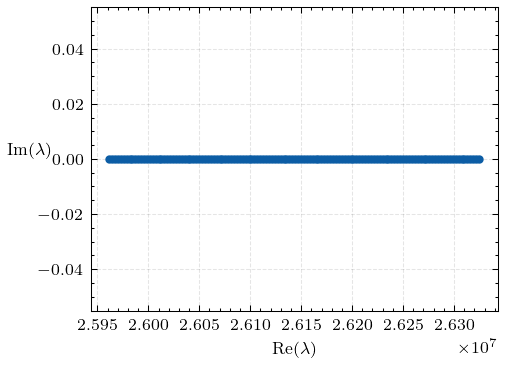

In [32]:
plt.plot(evals.real, evals.imag, ls="", ms=3)
plt.xlabel(r"$\mathrm{Re}(\lambda)$")
plt.ylabel(r"$\mathrm{Im}(\lambda)$", rotation="horizontal")
#plt.savefig(f"Antidark_eigs_c_{c_1:.4f}.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [33]:
# Tolerance for selecting nearly real eigenvalues
imag_tol = 1e-8

# Indices of eigenvalues with imaginary part close to zero
real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]

if real_like_idx.size == 0:
    raise RuntimeError("No eigenvalues found with imaginary part close to zero.")

# Among the nearly real eigenvalues, pick the one with largest real part
idx = real_like_idx[np.argmax(np.real(evals[real_like_idx]))]

lam = evals[idx]
vec = evecs[:, idx]

p = vec[:N]
q = vec[N:]

print("Largest non-complex eigenvalue =", lam)

Largest non-complex eigenvalue = (26324713.230202455+0j)


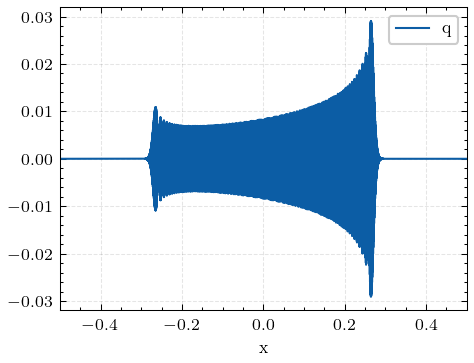

In [45]:
#plt.plot(x_dark, evecs[:, -2][:N].real, ms=0, label="p")
plt.plot(x_dark, evecs[:, -1][N:].real, ms=0, label="q")
plt.xlabel("x")

plt.xlim(-.5, .5)
#plt.ylabel("q")
plt.legend()
plt.show()


In [3]:
Nt = 10_000
tf = 2.5e-4

w_comp = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_comp.set_init_array(w_dark)
w_comp.solve()

Iteration  1  of  10000 . Newton Error:  2.0877241521303758e-16 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  2.1003314449226645e-16 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  2.0922626004783e-16 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  2.0907692559481784e-16 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  2.1158733442581762e-16 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  2.1218891690975758e-16 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  2.0996357114848382e-16 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  2.0866516753292237e-16 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  2.135451228908693e-16 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  2.131392842618742e-16 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  2.0762775176292586e-16 . Total iteration:  2
Iteration  12  of  10000 . Newton Error:  2.0720196707799

In [4]:
w_max = np.abs(w_comp.w).max(axis=1)

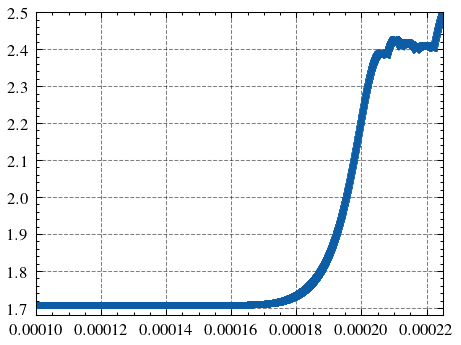

In [5]:
#j_max = 1628
plt.plot(w_comp.t, w_max, "x-", lw=.5, markeredgewidth=.5, ms=3)
plt.xlim(1e-4, 2.25e-4)
plt.ylim(1.68, 2.5)
plt.show()

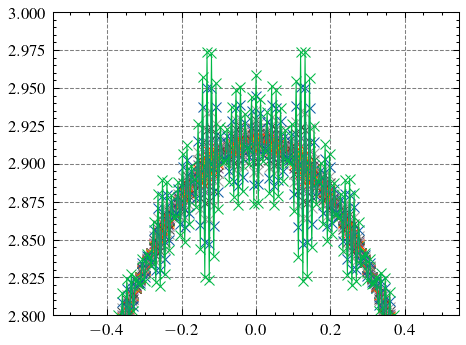

In [55]:
total_plot = len(w_comp.t[w_comp.t<0.00018])
indices = np.arange(0, total_plot, 100)
x_indices = np.where(np.abs(w_comp.x)<0.5)

for n in indices:
    plt.plot(w_comp.x[x_indices], norm(w_comp.w[n][x_indices]), "x-", lw=.5, markeredgewidth=.5, ms=5)

#plt.xlim(-0.02,0.02)
plt.ylim(2.8, 3)
plt.show()

In [13]:
e = w_comp.get_energy()

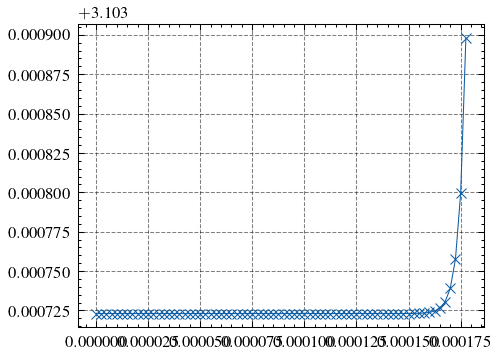

In [31]:
plt.plot(w_comp.t[indices], e[indices], "x-", lw=.5, markeredgewidth=.5, ms=5)

In [61]:
norm_grad_w = w_comp.h * np_norm(np.gradient(w_comp.w, w_comp.h, axis=1), np.inf, axis=1)

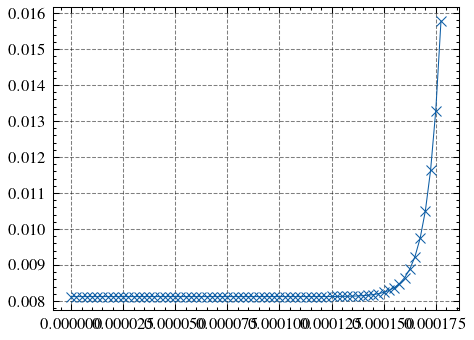

In [62]:
plt.plot(w_comp.t[indices], norm_grad_w[indices], "x-", lw=.5, markeredgewidth=.5, ms=5)
#plt.xlim(1.3e-4, 2.5e-4)
#plt.ylim(1.68, 2.5)

In [58]:
norm_grad_w = np.sqrt(w_comp.h) * np_norm(np.gradient(w_comp.w, w_comp.h, axis=1), 2, axis=1)

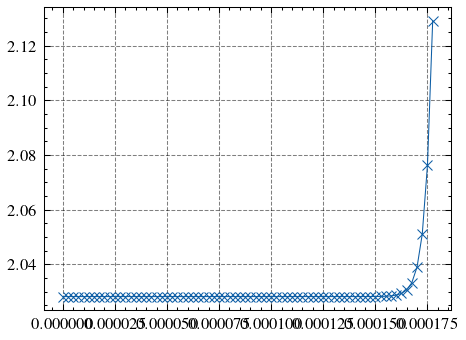

In [60]:
plt.plot(w_comp.t[indices], norm_grad_w[indices], "x-", lw=.5, markeredgewidth=.5, ms=5)
#plt.xlim(1.3e-4, 2.5e-4)
#plt.ylim(1.68, 2.5)

In [73]:
w_comp.t[1]-w_comp.t[0]

2.5002500250025003e-08

In [79]:
w_comp.dt

2.5002500250025003e-08

In [76]:
tf/(w_comp.Nt-1)

2.5002500250025003e-08

In [77]:
w_comp.t.shape

(10000,)

In [80]:
w_comp.t[-1]

0.00025